# Attention Mechanism — From the Math to Real Hugging Face Models

**Target:** students who already know basic neural networks/RNNs but have not implemented attention.

**Estimated time:** 90–120 minutes  
**Runtime:** Google Colab. CPU is sufficient; a free GPU is optional.

## Learning outcomes

By the end of this notebook, you should be able to:

1. Explain attention as **relevance-weighted retrieval**.
2. Compute attention manually: **score → softmax → weighted sum**.
3. Explain the roles of **Query (Q), Key (K), Value (V)**.
4. Implement **scaled dot-product self-attention**.
5. Explain and visualize a **causal mask**.
6. Inspect separate heads in **multi-head attention**.
7. Download and run lightweight pretrained models from the **Hugging Face Hub**.
8. Extract and visualize attention weights from a real Transformer model.

> We intentionally build the mechanism from small tensors first. The goal is not to train a language model in this notebook.

## 0. Colab setup

The notebook pins the stable `transformers` release used when this notebook was prepared.

PyTorch, NumPy and Matplotlib are already available in Google Colab, so only Hugging Face Transformers is installed here.

In [1]:
%pip -q install "transformers==5.17.0"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import math
import sys
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

import transformers
from transformers import (
    pipeline,
    AutoTokenizer,
    AutoModelForSequenceClassification,
)

torch.manual_seed(7)
np.random.seed(7)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIPELINE_DEVICE = 0 if torch.cuda.is_available() else -1

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Device:", DEVICE)

c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.4
PyTorch: 2.14.0+cpu
Transformers: 5.17.0
Device: cpu


# Part I — Attention from first principles

## 1. The core idea: retrieve information by relevance

Suppose each input token is represented by a vector.

For one **query**, attention does three things:

1. compare the query with every candidate key;
2. convert the comparison scores into normalized weights;
3. compute a weighted sum of the values.

For one query vector $q$, keys $k_i$, values $v_i$:

$$
s_i = q^\top k_i
$$

$$
\alpha_i = \operatorname{softmax}(s)_i
$$

$$
c = \sum_i \alpha_i v_i
$$

The output $c$ is called a **context vector**. It contains more information from positions that receive larger attention weights.

In [3]:
tokens = ["I", "love", "deep", "learning"]

# A tiny hand-made embedding matrix.
# Each row is one token vector.
X = torch.tensor([
    [1.0, 0.0, 1.0, 0.0],  # I
    [0.0, 1.0, 0.0, 1.0],  # love
    [1.0, 1.0, 0.0, 0.0],  # deep
    [1.0, 0.0, 0.0, 1.0],  # learning
])

query_index = 3
q = X[query_index]

scores = X @ q
weights = torch.softmax(scores, dim=0)
context = weights @ X

print("Query token:", tokens[query_index])
print("Scores:", scores)
print("Attention weights:", weights)
print("Sum of weights:", weights.sum().item())
print("Context vector:", context)

Query token: learning
Scores: tensor([1., 1., 1., 2.])
Attention weights: tensor([0.1749, 0.1749, 0.1749, 0.4754])
Sum of weights: 1.0
Context vector: tensor([0.8251, 0.3498, 0.1749, 0.6502])


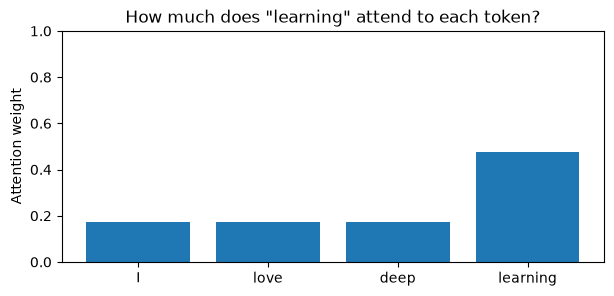

In [4]:
plt.figure(figsize=(7, 3))
plt.bar(tokens, weights.detach().cpu().numpy())
plt.ylim(0, 1)
plt.ylabel("Attention weight")
plt.title(f'How much does "{tokens[query_index]}" attend to each token?')
plt.show()

### What to notice

- The weights are non-negative because of softmax.
- The weights sum to 1.
- The context vector is **not** a copy of one token. It is a weighted mixture of value vectors.
- If the query changes, the attention distribution can change.

### Quick exercise

Change `query_index` from `3` to another token and rerun the two cells above.

**Question:** Why does the context vector change even though the input matrix `X` stays the same?

## 2. From one query to self-attention

In **self-attention**, every token becomes a query.

For an input matrix $X \in \mathbb{R}^{L \times d}$, we learn three projections:

$$
Q = XW_Q,\qquad K = XW_K,\qquad V = XW_V
$$

Then:

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
$$

Why divide by $\sqrt{d_k}$?  
When vector dimensions grow, dot products can become large. Large logits can make softmax extremely sharp. Scaling keeps the logits in a more useful numerical range.

In [5]:
L, d_model = X.shape
d_k = 4

# Fixed random matrices only for demonstration.
# In a real network these are trainable parameters.
W_Q = torch.randn(d_model, d_k) * 0.5
W_K = torch.randn(d_model, d_k) * 0.5
W_V = torch.randn(d_model, d_k) * 0.5

Q = X @ W_Q
K = X @ W_K
V = X @ W_V

raw_scores = Q @ K.T
scaled_scores = raw_scores / math.sqrt(d_k)
attn_weights = torch.softmax(scaled_scores, dim=-1)
context_vectors = attn_weights @ V

print("Q shape:", tuple(Q.shape))
print("K shape:", tuple(K.shape))
print("V shape:", tuple(V.shape))
print("Attention matrix shape:", tuple(attn_weights.shape))
print("Context vectors shape:", tuple(context_vectors.shape))
print("\nRow sums:", attn_weights.sum(dim=-1))

Q shape: (4, 4)
K shape: (4, 4)
V shape: (4, 4)
Attention matrix shape: (4, 4)
Context vectors shape: (4, 4)

Row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000])


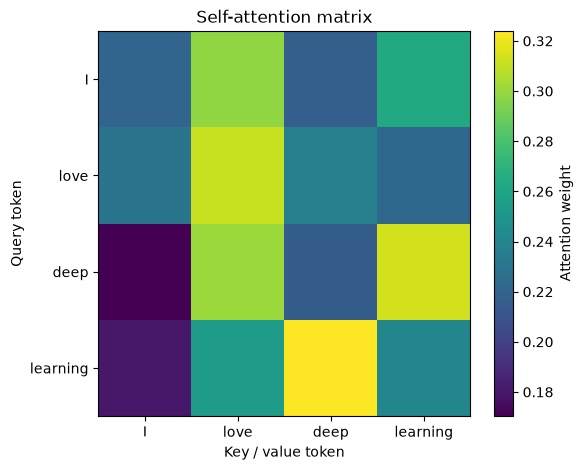

In [6]:
plt.figure(figsize=(6, 5))
plt.imshow(attn_weights.detach().cpu().numpy(), aspect="auto")
plt.colorbar(label="Attention weight")
plt.xticks(range(len(tokens)), tokens)
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("Key / value token")
plt.ylabel("Query token")
plt.title("Self-attention matrix")
plt.show()

### How to read the matrix

A cell at row $i$, column $j$ means:

> when updating token $i$, how much information is retrieved from token $j$?

Each row is a probability distribution over all key/value positions.

## 3. Verify our implementation with PyTorch SDPA

PyTorch provides:

```python
torch.nn.functional.scaled_dot_product_attention
```

For this check we reshape tensors to:

$$
[\text{batch}, \text{heads}, \text{sequence}, d_k]
$$

We use one batch and one head.

In [7]:
Q_4d = Q.unsqueeze(0).unsqueeze(0)
K_4d = K.unsqueeze(0).unsqueeze(0)
V_4d = V.unsqueeze(0).unsqueeze(0)

pytorch_context = F.scaled_dot_product_attention(
    Q_4d,
    K_4d,
    V_4d,
    dropout_p=0.0,
    is_causal=False,
)

manual_context = context_vectors.unsqueeze(0).unsqueeze(0)
max_abs_error = (manual_context - pytorch_context).abs().max().item()

print("Manual output shape:", tuple(manual_context.shape))
print("PyTorch output shape:", tuple(pytorch_context.shape))
print("Maximum absolute difference:", max_abs_error)

assert torch.allclose(manual_context, pytorch_context, atol=1e-6)
print("Check passed.")

Manual output shape: (1, 1, 4, 4)
PyTorch output shape: (1, 1, 4, 4)
Maximum absolute difference: 1.1920928955078125e-07
Check passed.


## 4. Causal attention: do not look into the future

A decoder-style language model predicts the next token from previous tokens.
Therefore, token $i$ must not attend to positions $j > i$.

For four positions, the allowed pattern is:

$$
\begin{bmatrix}
1 & 0 & 0 & 0\\
1 & 1 & 0 & 0\\
1 & 1 & 1 & 0\\
1 & 1 & 1 & 1
\end{bmatrix}
$$

Masked positions are assigned $-\infty$ **before softmax**, so their probabilities become zero.

In [8]:
causal_mask = torch.tril(torch.ones(L, L, dtype=torch.bool))

masked_scores = scaled_scores.masked_fill(~causal_mask, float("-inf"))
causal_weights = torch.softmax(masked_scores, dim=-1)
causal_context = causal_weights @ V

print("Causal mask:")
print(causal_mask.int())

print("\nCausal attention weights:")
print(torch.round(causal_weights * 1000) / 1000)

Causal mask:
tensor([[1, 0, 0, 0],
        [1, 1, 0, 0],
        [1, 1, 1, 0],
        [1, 1, 1, 1]], dtype=torch.int32)

Causal attention weights:
tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.4240, 0.5760, 0.0000, 0.0000],
        [0.2480, 0.4380, 0.3140, 0.0000],
        [0.1800, 0.2550, 0.3240, 0.2410]])


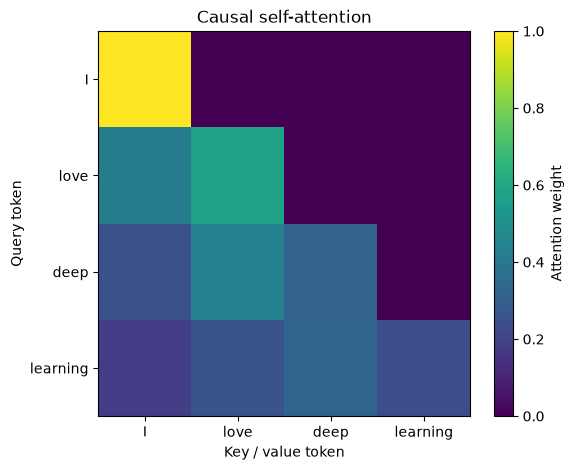

In [9]:
plt.figure(figsize=(6, 5))
plt.imshow(causal_weights.detach().cpu().numpy(), aspect="auto")
plt.colorbar(label="Attention weight")
plt.xticks(range(len(tokens)), tokens)
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("Key / value token")
plt.ylabel("Query token")
plt.title("Causal self-attention")
plt.show()

In [10]:
pytorch_causal = F.scaled_dot_product_attention(
    Q_4d,
    K_4d,
    V_4d,
    dropout_p=0.0,
    is_causal=True,
)

manual_causal = causal_context.unsqueeze(0).unsqueeze(0)
assert torch.allclose(manual_causal, pytorch_causal, atol=1e-6)
print("Causal attention check passed.")

Causal attention check passed.


### Common masking mistake

Do not confuse the boolean-mask conventions of different APIs.

- `torch.nn.functional.scaled_dot_product_attention`: boolean `True` means **this position is allowed to participate in attention**.
- `torch.nn.MultiheadAttention` padding masks: boolean `True` means **ignore/mask this position**.

Always check the API documentation before reusing one mask in another attention API.

## 5. Multi-head attention

One attention matrix gives one learned way to relate tokens.

Multi-head attention creates several attention heads in parallel. Each head has its own projected representation and can learn a different relationship pattern.

For model dimension $d_{\text{model}}$ and $h$ heads, a common setup uses:

$$
d_{\text{head}} = \frac{d_{\text{model}}}{h}
$$

We use PyTorch `nn.MultiheadAttention` and request **per-head** attention matrices.

In [11]:
torch.manual_seed(11)

embed_dim = 8
num_heads = 2
X_mha = torch.randn(1, len(tokens), embed_dim)

mha = nn.MultiheadAttention(
    embed_dim=embed_dim,
    num_heads=num_heads,
    batch_first=True,
)

mha_output, mha_weights = mha(
    X_mha,
    X_mha,
    X_mha,
    need_weights=True,
    average_attn_weights=False,
)

print("Input shape:", tuple(X_mha.shape))
print("Output shape:", tuple(mha_output.shape))
print("Attention weights shape:", tuple(mha_weights.shape))
print("Expected: [batch, heads, query_length, key_length]")

Input shape: (1, 4, 8)
Output shape: (1, 4, 8)
Attention weights shape: (1, 2, 4, 4)
Expected: [batch, heads, query_length, key_length]


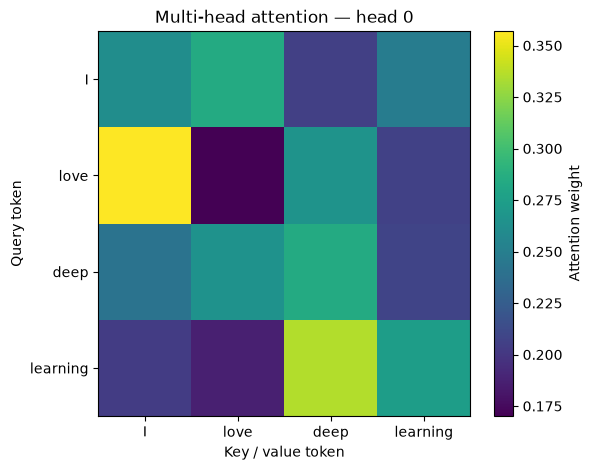

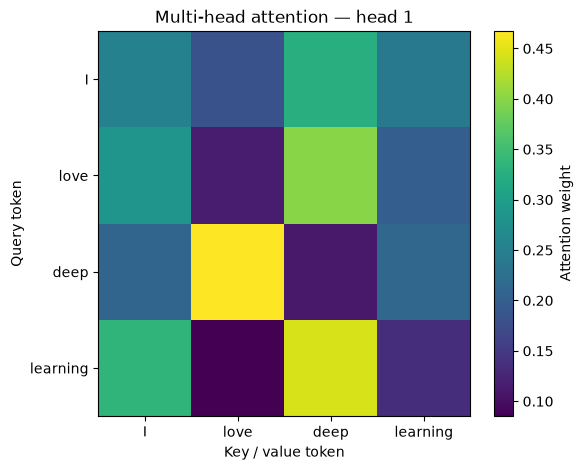

In [12]:
for head in range(num_heads):
    plt.figure(figsize=(6, 5))
    plt.imshow(mha_weights[0, head].detach().cpu().numpy(), aspect="auto")
    plt.colorbar(label="Attention weight")
    plt.xticks(range(len(tokens)), tokens)
    plt.yticks(range(len(tokens)), tokens)
    plt.xlabel("Key / value token")
    plt.ylabel("Query token")
    plt.title(f"Multi-head attention — head {head}")
    plt.show()

### Interpretation warning

An attention heatmap is useful for inspecting the mechanism, but **an attention weight is not automatically a complete causal explanation of a model prediction**.

Treat it as: *where this attention head retrieves information from*, not as proof that one token alone caused the final output.

# Part II — Pull lightweight models from Hugging Face and run them

This section uses the standard Hugging Face workflow:

1. choose a model ID from the Hub;
2. call `from_pretrained(...)` or `pipeline(...)`;
3. the config/tokenizer/weights are downloaded and cached;
4. run inference locally in the Colab runtime.

We use two relatively small models:

- **DistilBERT SST-2** — encoder-style Transformer for sentiment classification.
- **DistilGPT2** — decoder-style Transformer for text generation.

If you only want a very fast smoke test for generation, replace DistilGPT2 by `sshleifer/tiny-gpt2`. It is much smaller, but its generated text is not intended as a quality demonstration.

## 6. Model 1 — DistilBERT sentiment classifier

High-level inference with `pipeline(...)`.

In [13]:
CLASSIFIER_ID = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"

classifier = pipeline(
    task="text-classification",
    model=CLASSIFIER_ID,
    device=PIPELINE_DEVICE,
)

examples = [
    "The lecture was clear and surprisingly useful.",
    "The explanation was confusing and I learned almost nothing.",
]

classifier(examples)

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1133.90it/s]


[{'label': 'POSITIVE', 'score': 0.9996570348739624},
 {'label': 'NEGATIVE', 'score': 0.9992247819900513}]

### What `pipeline` hides from you

Conceptually:

```text
text
  → tokenizer
  → token IDs + attention mask
  → Transformer model
  → logits
  → softmax
  → label
```

Next we open the model and inspect its actual self-attention matrices.

## 7. Inspect attention inside a real DistilBERT model

We explicitly request the **eager** attention implementation.

Why? Optimized attention backends such as SDPA are designed for efficiency and may avoid materializing the full attention matrix. For teaching, we explicitly want the weights.

Hugging Face model outputs return attentions with shape:

$$
[\text{batch}, \text{heads}, \text{sequence}, \text{sequence}]
$$

for each Transformer layer.

In [14]:
tokenizer = AutoTokenizer.from_pretrained(CLASSIFIER_ID)

model = AutoModelForSequenceClassification.from_pretrained(
    CLASSIFIER_ID,
    attn_implementation="eager",
).to(DEVICE)

model.eval()

sentence = "The movie was not good, but the ending was excellent."
batch = tokenizer(sentence, return_tensors="pt")
batch = {k: v.to(DEVICE) for k, v in batch.items()}

with torch.no_grad():
    outputs = model(**batch, output_attentions=True)

print("Logits shape:", tuple(outputs.logits.shape))
print("Number of attention layers:", len(outputs.attentions))
print("Layer 0 attention shape:", tuple(outputs.attentions[0].shape))

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 834.19it/s]

Logits shape: (1, 2)
Number of attention layers: 6
Layer 0 attention shape: (1, 12, 14, 14)


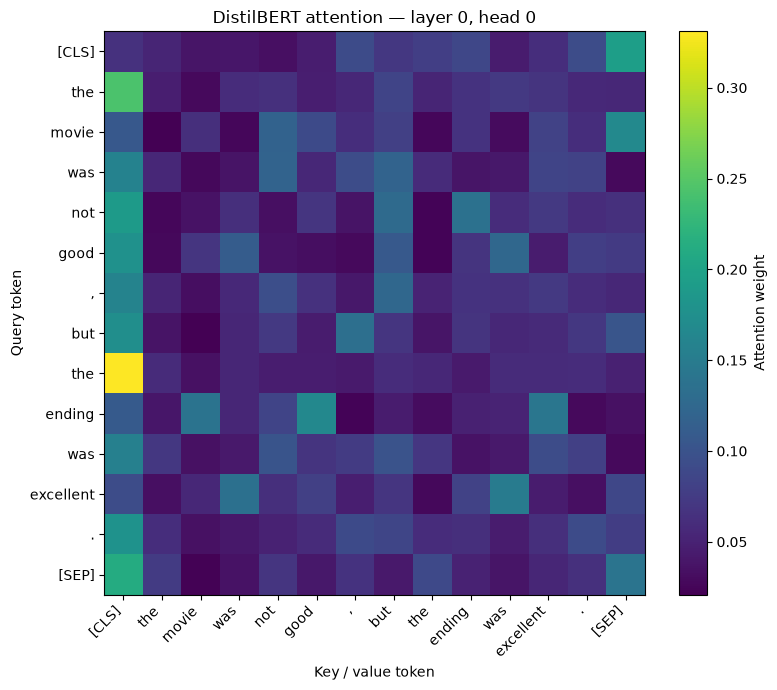

In [15]:
token_ids = batch["input_ids"][0].detach().cpu().tolist()
token_labels = tokenizer.convert_ids_to_tokens(token_ids)

layer = 0
head = 0
real_attention = outputs.attentions[layer][0, head].detach().cpu()

plt.figure(figsize=(8, 7))
plt.imshow(real_attention.numpy(), aspect="auto")
plt.colorbar(label="Attention weight")
plt.xticks(range(len(token_labels)), token_labels, rotation=45, ha="right")
plt.yticks(range(len(token_labels)), token_labels)
plt.xlabel("Key / value token")
plt.ylabel("Query token")
plt.title(f"DistilBERT attention — layer {layer}, head {head}")
plt.tight_layout()
plt.show()

In [16]:
row_sums = real_attention.sum(dim=-1)
print(row_sums)
print("Maximum deviation from 1:", (row_sums - 1).abs().max().item())

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000])
Maximum deviation from 1: 1.1920928955078125e-07


### Exploration tasks

Try these changes one at a time:

1. Change `head = 0` to another head.
2. Change `layer = 0` to a later layer.
3. Compare:
   - `"The course is not difficult."`
   - `"The course is difficult."`
4. Compare the `[CLS]` row between heads.
5. Find a head whose attention is concentrated on only a few tokens.

Do not expect every head to have an obvious linguistic interpretation.

## 8. Model 2 — DistilGPT2 text generation

DistilGPT2 is a decoder-style autoregressive model.

At generation step $t$, it predicts the next token using the prefix:

$$
x_1, x_2, \ldots, x_t
$$

Its self-attention is causal, so a position cannot use future tokens.

In [17]:
GENERATOR_ID = "distilbert/distilgpt2"

generator = pipeline(
    task="text-generation",
    model=GENERATOR_ID,
    device=PIPELINE_DEVICE,
)

prompt = "Attention in neural networks is useful because"

generated = generator(
    prompt,
    max_new_tokens=35,
    do_sample=False,
    pad_token_id=generator.tokenizer.eos_token_id,
)

print(generated[0]["generated_text"])

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 238.59it/s]
[transformers] Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=35) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_

Attention in neural networks is useful because it allows us to see the neural networks that are involved in the processing of information.




















### Optional ultra-light alternative

If download speed or RAM is extremely limited, use `sshleifer/tiny-gpt2` instead.

In [18]:
# Optional: very small smoke-test model.
# Uncomment to run it.
#
# tiny_generator = pipeline(
#     task="text-generation",
#     model="sshleifer/tiny-gpt2",
#     device=PIPELINE_DEVICE,
# )
#
# tiny_generator(
#     "Deep learning",
#     max_new_tokens=20,
#     do_sample=False,
#     pad_token_id=tiny_generator.tokenizer.eos_token_id,
# )

# Part III — Exercises

## Exercise 1 — Remove softmax

Temporarily replace softmax by raw scores in the toy example.

1. Can weights become negative?
2. Do weights still sum to 1?
3. What happens to the scale of the output vector?
4. Why is this inconvenient if we want a normalized relevance distribution?

---

## Exercise 2 — Remove the scaling factor

Compare $QK^\top$ with $QK^\top / \sqrt{d_k}$ for larger values of `d_k`, such as 16, 64, and 256.

Measure the entropy of each softmax row:

$$
H(p) = -\sum_i p_i \log p_i
$$

**Question:** does unscaled attention become unusually sharp as dimension grows?

---

## Exercise 3 — Break the causal mask

Let token 0 attend to token 3.

Explain why this is **information leakage** during next-token prediction.

---

## Exercise 4 — Compare two DistilBERT heads

Select two heads from the same layer and visualize them separately.
Write 3–5 sentences describing similarities and differences.

Avoid claiming that a head "understands" a grammatical concept unless your experiment actually supports that claim.

---

## Exercise 5 — Pipeline vs direct model API

For DistilBERT:

1. run the same sentence through `pipeline`;
2. tokenize it manually;
3. call the model directly;
4. apply softmax to `outputs.logits`;
5. verify that both approaches produce the same label.

### Exercise 1 — Remove softmax

We use raw scores as the "weights" in two cases: the toy example in section 1 (`X @ q`), and the scaled scores $QK^\top/\sqrt{d_k}$ in section 2.


In [19]:
# Case 1: toy example from section 1
raw_weights_toy = scores                      # no softmax
raw_context_toy = raw_weights_toy @ X

print("Toy example")
print("  softmax weights:", weights.numpy().round(4), "| sum =", round(weights.sum().item(), 4))
print("  raw weights    :", raw_weights_toy.numpy(), "| sum =", raw_weights_toy.sum().item())
print("  ||context|| with softmax:", round(context.norm().item(), 4))
print("  ||context|| without     :", round(raw_context_toy.norm().item(), 4))

# Case 2: Q/K self-attention from section 2
raw_weights_qk = scaled_scores                # no softmax
raw_context_qk = raw_weights_qk @ V

print("\nQ/K self-attention")
print("  raw weights:\n", raw_weights_qk.numpy().round(3))
print("  negative weights:", int((raw_weights_qk < 0).sum()), "/", raw_weights_qk.numel())
print("  row sums without softmax:", raw_weights_qk.sum(dim=-1).numpy().round(3))
print("  row sums with softmax   :", attn_weights.sum(dim=-1).numpy().round(3))
print("  mean ||context|| with softmax:", round(context_vectors.norm(dim=-1).mean().item(), 4))
print("  mean ||context|| without     :", round(raw_context_qk.norm(dim=-1).mean().item(), 4))


Toy example
  softmax weights: [0.1749 0.1749 0.1749 0.4754] | sum = 1.0
  raw weights    : [1. 1. 1. 2.] | sum = 5.0
  ||context|| with softmax: 1.121
  ||context|| without     : 5.4772

Q/K self-attention
  raw weights:
 [[ 0.138  0.441  0.121  0.316]
 [-0.231  0.074 -0.198 -0.262]
 [ 0.371  0.939  0.606  0.981]
 [-0.029  0.32   0.558  0.26 ]]
  negative weights: 4 / 16
  row sums without softmax: [ 1.015 -0.618  2.898  1.109]
  row sums with softmax   : [1. 1. 1. 1.]
  mean ||context|| with softmax: 0.6466
  mean ||context|| without     : 1.0366


**Answer (Exercise 1):** 

1. **Có thể âm.** Trong ví dụ toy, các score `X @ q` không âm chỉ vì mọi phần tử của `X` đều ≥ 0. Với $QK^\top/\sqrt{d_k}$ thì có 4/16 score bị âm. Một "trọng số" âm nghĩa là trừ đi thông tin của token đó, và không còn diễn giải được là "mức độ liên quan".
2. **Không còn tổng bằng 1.** Tổng mỗi hàng là 5.0 ở ví dụ toy, và [1.02, −0.62, 2.90, 1.11] ở ví dụ Q/K. Có hàng còn có tổng âm.
3. **Độ lớn của output bị trôi theo độ lớn của score.** Norm của context vector tăng từ 1.12 lên 5.48 ở ví dụ toy (gần 5 lần, đúng bằng tổng các score). Output không còn là trung bình có trọng số của các value, nên không nằm trong vùng giá trị của `V`. Câu dài hơn hoặc score lớn hơn sẽ làm output lớn hơn tương ứng.
4. Softmax bảo đảm các trọng số không âm và có tổng bằng 1. Nhờ vậy mỗi hàng là một phân phối xác suất trên các token, và output là trung bình có trọng số (convex combination) của các value. Output có scale ổn định, không phụ thuộc vào độ dài câu, và đọc được thành "phần trăm chú ý". Nếu bỏ softmax, ta mất cả ba tính chất này, và việc train cũng kém ổn định hơn.


### Exercise 2 — Remove the scaling factor

Use random $Q, K \sim \mathcal{N}(0, 1)$ with `L = 10` tokens. Averaged over 200 trials, compare the mean entropy of each softmax row. The maximum possible entropy (uniform attention) is $\log L \approx 2.30$.


In [20]:
torch.manual_seed(0)
L_ex2, n_trials = 10, 200
max_entropy = math.log(L_ex2)


def row_entropy(p):
    return -(p * torch.log(p.clamp_min(1e-12))).sum(dim=-1)


ex2_rows = []
for d in [4, 16, 64, 256]:
    Q_r = torch.randn(n_trials, L_ex2, d)
    K_r = torch.randn(n_trials, L_ex2, d)
    s = Q_r @ K_r.transpose(-2, -1)

    for name, sc in [("unscaled QK^T", s), ("scaled QK^T/sqrt(d_k)", s / math.sqrt(d))]:
        p = torch.softmax(sc, dim=-1)
        ex2_rows.append({
            "d_k": d,
            "Scores": name,
            "Score std": round(sc.std().item(), 2),
            "Mean entropy": round(row_entropy(p).mean().item(), 3),
            "Mean max weight": round(p.max(dim=-1).values.mean().item(), 3),
        })

print(f"Maximum entropy log(L) = {max_entropy:.3f}")
for row in ex2_rows:
    print(row)


Maximum entropy log(L) = 2.303
{'d_k': 4, 'Scores': 'unscaled QK^T', 'Score std': 2.01, 'Mean entropy': 1.426, 'Mean max weight': 0.499}
{'d_k': 4, 'Scores': 'scaled QK^T/sqrt(d_k)', 'Score std': 1.01, 'Mean entropy': 1.945, 'Mean max weight': 0.308}
{'d_k': 16, 'Scores': 'unscaled QK^T', 'Score std': 4.02, 'Mean entropy': 0.753, 'Mean max weight': 0.724}
{'d_k': 16, 'Scores': 'scaled QK^T/sqrt(d_k)', 'Score std': 1.0, 'Mean entropy': 1.933, 'Mean max weight': 0.314}
{'d_k': 64, 'Scores': 'unscaled QK^T', 'Score std': 7.97, 'Mean entropy': 0.342, 'Mean max weight': 0.869}
{'d_k': 64, 'Scores': 'scaled QK^T/sqrt(d_k)', 'Score std': 1.0, 'Mean entropy': 1.924, 'Mean max weight': 0.321}
{'d_k': 256, 'Scores': 'unscaled QK^T', 'Score std': 15.94, 'Mean entropy': 0.16, 'Mean max weight': 0.934}
{'d_k': 256, 'Scores': 'scaled QK^T/sqrt(d_k)', 'Score std': 1.0, 'Mean entropy': 1.924, 'Mean max weight': 0.322}


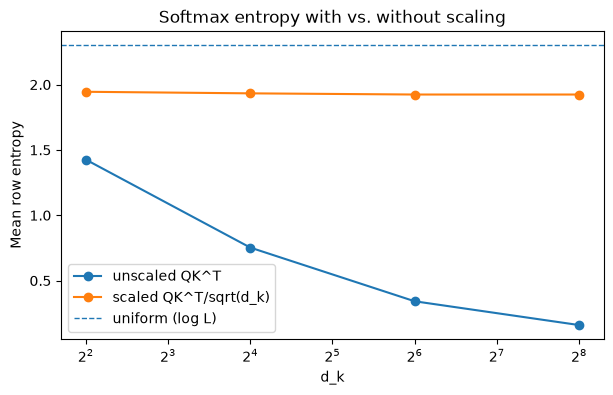

In [21]:
d_values = [4, 16, 64, 256]
plt.figure(figsize=(7, 4))
for name in ["unscaled QK^T", "scaled QK^T/sqrt(d_k)"]:
    plt.plot(d_values, [r["Mean entropy"] for r in ex2_rows if r["Scores"] == name], marker="o", label=name)
plt.axhline(max_entropy, linestyle="--", linewidth=1, label="uniform (log L)")
plt.xscale("log", base=2)
plt.xlabel("d_k")
plt.ylabel("Mean row entropy")
plt.title("Softmax entropy with vs. without scaling")
plt.legend()
plt.show()


**Answer (Exercise 2):** **Có.** Nếu không scale, độ lệch chuẩn của score tăng theo $\sqrt{d_k}$ (2.0 → 4.0 → 8.0 → 15.9). Softmax vì thế ngày càng giống argmax: entropy trung bình giảm từ 1.43 xuống 0.75, 0.34 rồi 0.16, và trọng số lớn nhất tăng từ 0.50 lên 0.93. Khi $d_k = 256$, gần như mỗi hàng chỉ chú ý vào một token. Khi chia cho $\sqrt{d_k}$, độ lệch chuẩn của score giữ ở khoảng 1, và entropy ổn định quanh 1.92–1.95 (tối đa là $\log 10 \approx 2.30$) với mọi $d_k$. Ngoài ra, softmax bị bão hòa sẽ có gradient gần bằng 0, làm model khó học. Đây là lý do Transformer dùng hệ số $1/\sqrt{d_k}$.


### Exercise 3 — Break the causal mask

Open one "leak" in the mask: token 0 is allowed to see token 3. Then change the **future** token (row 3 of `X`) and check whether the output at position 0 changes.


In [22]:
broken_mask = causal_mask.clone()
broken_mask[0, 3] = True     # token 0 can now see token 3 (in the future)


def causal_output(X_in, mask):
    Q_, K_, V_ = X_in @ W_Q, X_in @ W_K, X_in @ W_V
    s = (Q_ @ K_.T / math.sqrt(d_k)).masked_fill(~mask, float("-inf"))
    w = torch.softmax(s, dim=-1)
    return w, w @ V_


w_ok, out_ok = causal_output(X, causal_mask)
w_bad, out_bad = causal_output(X, broken_mask)
print("Row 0 weights, correct mask:", w_ok[0].numpy().round(3))
print("Row 0 weights, broken mask :", w_bad[0].numpy().round(3))

# Change only the future token "learning" (position 3).
X_changed = X.clone()
X_changed[3] = torch.tensor([0.0, 0.0, 5.0, 5.0])

_, out_ok_changed = causal_output(X_changed, causal_mask)
_, out_bad_changed = causal_output(X_changed, broken_mask)

print("\nChange in output at position 0 after changing token 3:")
print("  correct mask:", round((out_ok_changed[0] - out_ok[0]).abs().max().item(), 6))
print("  broken mask :", round((out_bad_changed[0] - out_bad[0]).abs().max().item(), 6))


Row 0 weights, correct mask: [1. 0. 0. 0.]
Row 0 weights, broken mask : [0.456 0.    0.    0.544]

Change in output at position 0 after changing token 3:
  correct mask: 0.0
  broken mask : 4.29475


**Answer (Exercise 3):** Khi mở mask ở ô [0, 3], hàng 0 chuyển từ [1, 0, 0, 0] sang [0.456, 0, 0, 0.544]: hơn một nửa thông tin của vị trí 0 giờ lấy từ token 3. Ta thử thay đổi **chỉ** token tương lai "learning". Với mask đúng, output ở vị trí 0 không đổi (sai khác 0.0). Với mask bị hỏng, output thay đổi tới 4.29. Đó là **rò rỉ thông tin (information leakage)**: khi train mô hình dự đoán token tiếp theo, vị trí 0 phải dự đoán token 1 chỉ từ quá khứ. Nếu nó nhìn thấy token tương lai (ở đây là token 3, và cùng cách đó có thể là chính token 1 cần đoán), model có thể "chép đáp án" thay vì học cách dự đoán. Loss khi train sẽ thấp một cách giả tạo. Nhưng khi sinh văn bản, token tương lai chưa tồn tại, nên model sẽ hoạt động kém hơn nhiều so với những gì loss khi train cho thấy.


### Exercise 4 — Compare two DistilBERT heads

Use the sentence from section 7. First compute summary statistics for every head in layer 0 (entropy, and the average attention on `[CLS]`, `[SEP]`, the token itself, the previous token, and the next token). Then plot two contrasting heads.


{'head': 0, 'entropy': 2.49, '->[CLS]': 0.17, '->[SEP]': 0.08, '->self': 0.06, '->previous': 0.08, '->next': 0.06}
{'head': 1, 'entropy': 1.8, '->[CLS]': 0.06, '->[SEP]': 0.05, '->self': 0.11, '->previous': 0.06, '->next': 0.06}
{'head': 2, 'entropy': 0.57, '->[CLS]': 0.37, '->[SEP]': 0.02, '->self': 0.07, '->previous': 0.7, '->next': 0.0}
{'head': 3, 'entropy': 1.33, '->[CLS]': 0.17, '->[SEP]': 0.07, '->self': 0.13, '->previous': 0.49, '->next': 0.01}
{'head': 4, 'entropy': 2.22, '->[CLS]': 0.19, '->[SEP]': 0.1, '->self': 0.15, '->previous': 0.06, '->next': 0.06}
{'head': 5, 'entropy': 1.99, '->[CLS]': 0.22, '->[SEP]': 0.08, '->self': 0.07, '->previous': 0.12, '->next': 0.05}
{'head': 6, 'entropy': 2.14, '->[CLS]': 0.11, '->[SEP]': 0.05, '->self': 0.11, '->previous': 0.07, '->next': 0.09}
{'head': 7, 'entropy': 1.65, '->[CLS]': 0.46, '->[SEP]': 0.09, '->self': 0.04, '->previous': 0.13, '->next': 0.04}
{'head': 8, 'entropy': 1.76, '->[CLS]': 0.15, '->[SEP]': 0.15, '->self': 0.08, '->pr

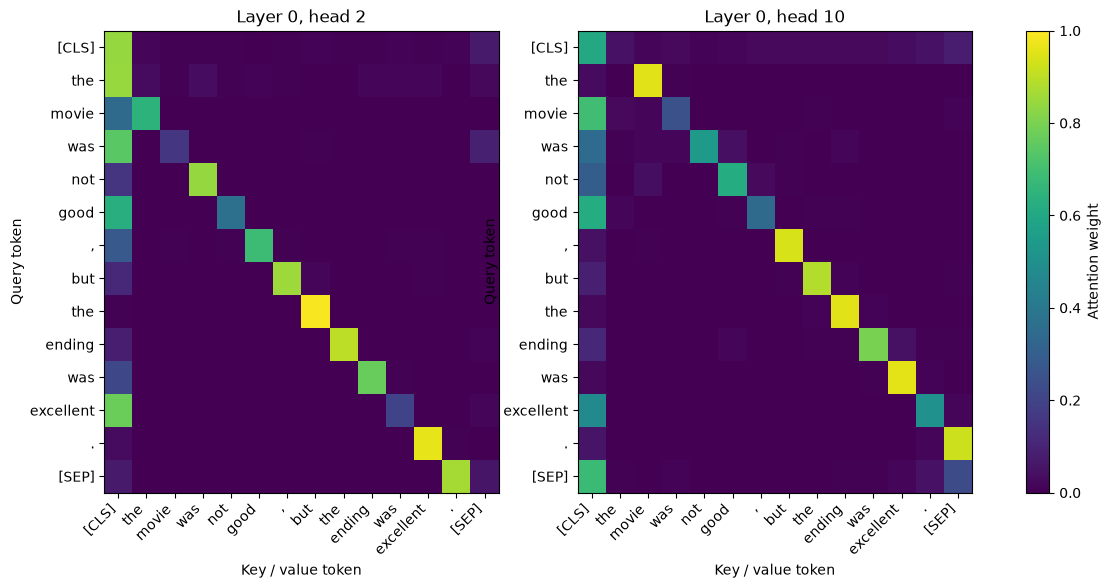

In [23]:
EX4_LAYER = 0
HEAD_A, HEAD_B = 2, 10

layer_attention = outputs.attentions[EX4_LAYER][0].detach().cpu()   # (heads, L, L)
n_tok = layer_attention.shape[-1]
pos = torch.arange(n_tok)

head_stats = []
for h in range(layer_attention.shape[0]):
    a = layer_attention[h]
    head_stats.append({
        "head": h,
        "entropy": round(row_entropy(a).mean().item(), 2),
        "->[CLS]": round(a[:, 0].mean().item(), 2),
        "->[SEP]": round(a[:, -1].mean().item(), 2),
        "->self": round(a[pos, pos].mean().item(), 2),
        "->previous": round(a[pos[1:], pos[:-1]].mean().item(), 2),
        "->next": round(a[pos[:-1], pos[1:]].mean().item(), 2),
    })

for row in head_stats:
    print(row)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, h in zip(axes, [HEAD_A, HEAD_B]):
    im = ax.imshow(layer_attention[h].numpy(), aspect="auto", vmin=0, vmax=1)
    ax.set_xticks(range(n_tok))
    ax.set_xticklabels(token_labels, rotation=45, ha="right")
    ax.set_yticks(range(n_tok))
    ax.set_yticklabels(token_labels)
    ax.set_xlabel("Key / value token")
    ax.set_ylabel("Query token")
    ax.set_title(f"Layer {EX4_LAYER}, head {h}")
fig.colorbar(im, ax=axes, label="Attention weight")
plt.show()


**Answer (Exercise 4):** Chọn layer 0, head 2 và head 10, vì đây là hai head có entropy thấp nhất (0.57 và 0.70). Hai head này tập trung hơn nhiều so với các head gần như đồng đều như head 0 (2.49, mức tối đa là $\log 14 \approx 2.64$). Điểm khác biệt là chúng đối xứng nhau: head 2 dồn trung bình 0.70 trọng số vào **token đứng trước** và gần như 0 vào token đứng sau, còn head 10 dồn 0.67 vào **token đứng sau** và chỉ 0.01 vào token đứng trước. Cả hai đều đặt một phần trọng số lên `[CLS]` (0.37 và 0.29). Với head 2, điều này một phần là do `[CLS]` chính là token đứng trước của từ đầu tiên. Đây là các mẫu hình theo **vị trí tương đối**, nằm ở layer đầu tiên, và không phụ thuộc vào nghĩa của từ. Vì chỉ quan sát trên một câu duy nhất, ta không thể kết luận hai head này "hiểu" một khái niệm ngữ pháp nào. Chỉ có thể nói rằng chúng có vẻ trộn thông tin từ các token lân cận.


### Exercise 5 — Pipeline vs direct model API


In [24]:
ex5_sentence = "The lecture was clear and surprisingly useful."

# 1. pipeline
pipe_result = classifier(ex5_sentence)[0]

# 2. tokenize manually
ex5_batch = tokenizer(ex5_sentence, return_tensors="pt")
ex5_batch = {k: v.to(DEVICE) for k, v in ex5_batch.items()}
print("Tokens:", tokenizer.convert_ids_to_tokens(ex5_batch["input_ids"][0]))

# 3. call the model directly
with torch.no_grad():
    ex5_logits = model(**ex5_batch).logits

# 4. softmax on the logits
ex5_probs = torch.softmax(ex5_logits, dim=-1)[0].cpu()
pred_id = int(ex5_probs.argmax())
direct_label = model.config.id2label[pred_id]

print("Logits:", ex5_logits[0].cpu().numpy().round(4))
print("Probabilities:", {model.config.id2label[i]: round(p.item(), 6) for i, p in enumerate(ex5_probs)})
print("Pipeline:", pipe_result)
print("Direct  :", {"label": direct_label, "score": ex5_probs[pred_id].item()})

# 5. check that both give the same result
assert pipe_result["label"] == direct_label
assert abs(pipe_result["score"] - ex5_probs[pred_id].item()) < 1e-5
print("Check passed: same label and same score.")


Tokens: ['[CLS]', 'the', 'lecture', 'was', 'clear', 'and', 'surprisingly', 'useful', '.', '[SEP]']
Logits: [-3.8779  4.0996]
Probabilities: {'NEGATIVE': 0.000343, 'POSITIVE': 0.999657}
Pipeline: {'label': 'POSITIVE', 'score': 0.9996570348739624}
Direct  : {'label': 'POSITIVE', 'score': 0.9996570348739624}
Check passed: same label and same score.


**Answer (Exercise 5):** Cả hai cách đều cho **POSITIVE với score 0.999657**, trùng khớp tới sai số dấu phẩy động. Gọi model trực tiếp cho logits [−3.88, 4.10]; áp softmax lên logits được [0.000343, 0.999657], rồi `argmax` kết hợp với `model.config.id2label` cho ra nhãn POSITIVE. `pipeline` thực hiện đúng chuỗi bước đó: tokenizer → model → softmax → argmax → ánh xạ sang tên nhãn. Nó chỉ gói các bước này lại cho gọn.


# Summary

The mechanism can be reduced to four steps:

$$
\boxed{
QK^\top
\rightarrow
\text{scale/mask}
\rightarrow
\text{softmax}
\rightarrow
\text{weighted sum of }V
}
$$

- **Q** asks what information is needed.
- **K** describes what each position can be matched by.
- **V** contains the information to retrieve.
- **Self-attention** uses positions from the same sequence as Q/K/V sources.
- **Causal attention** prevents access to future tokens.
- **Multi-head attention** performs several retrieval patterns in parallel.
- Hugging Face `pipeline(...)` is a high-level inference interface; `AutoTokenizer` + `AutoModel...` exposes lower-level outputs such as attention matrices.

The next natural step is to place multi-head attention inside a full **Transformer block** with LayerNorm, residual connections, and a feed-forward network.

## References checked before preparing the notebook

- PyTorch documentation — `torch.nn.functional.scaled_dot_product_attention`
- PyTorch documentation — `torch.nn.MultiheadAttention`
- Hugging Face Transformers documentation — Pipelines
- Hugging Face Transformers documentation — Model outputs / attentions
- Hugging Face Transformers documentation — attention implementations
- Hugging Face Hub model cards:
  - `distilbert/distilbert-base-uncased-finetuned-sst-2-english`
  - `distilbert/distilgpt2`
  - `sshleifer/tiny-gpt2`

The code intentionally follows the current documented APIs rather than older tutorial syntax.